<a href="https://colab.research.google.com/github/Desire-in-tech/music-genre-classification/blob/task-06%2Fmusic-genre-classification/notebooks/task_06_music_genre_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 6 — Music Genre Classification

**Goal:** classify GTZAN recordings into music genres and compare (1) track-level Librosa tabular features with Scikit-learn and (2) complete-track log-Mel spectrograms with a CNN.

This notebook is designed for Google Colab. Run top-to-bottom. The audio dataset and generated caches/models stay in the Colab runtime and are not committed to Git. Both approaches use the same stratified recording-level split; no track contributes data to more than one split.

## 1. Runtime setup

The notebook clones the project working branch, installs its package and dependencies, and records the runtime. For the CNN, select **Runtime → Change runtime type → T4 GPU** if available. The tabular experiment can run on CPU.

In [1]:
import os, sys, json, random, platform, subprocess
from pathlib import Path

REPO_URL = "https://github.com/Desire-in-tech/music-genre-classification.git"
BRANCH = "task-06/music-genre-classification"
PROJECT_DIR = Path("/content/music-genre-classification")

if not (PROJECT_DIR / "pyproject.toml").exists():
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(PROJECT_DIR)], check=True)
%cd /content/music-genre-classification
%pip -q install -r requirements.txt
%pip -q install -e . kagglehub tqdm

# Make the src-layout package importable in Colab immediately, even if editable-install path hooks lag.
sys.path.insert(0, str(PROJECT_DIR / "src"))

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
import numpy as np
np.random.seed(SEED)

import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("GPU devices:", subprocess.run(["bash","-lc","nvidia-smi"],capture_output=True,text=True).stdout[:1200] or "No NVIDIA GPU detected")


/content/music-genre-classification
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for music-genre-classification (pyproject.toml) ... done
Python: 3.13.16
NumPy: 2.4.6
GPU devices: Wed Nov 18 11:08:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+==========

## 2. Download and locate GTZAN

The recommended Kaggle collection is downloaded with KaggleHub. If Kaggle requires authentication, create a Kaggle API token in your Kaggle account, upload `kaggle.json` when prompted, and authenticate in the next cell. Do not commit the token.

In [6]:
from pathlib import Path
import sys
import os

# Be robust if this section is rerun after a Colab runtime restart.
PROJECT_DIR = Path("/content/music-genre-classification")
PACKAGE_SRC = PROJECT_DIR / "src"
if not (PACKAGE_SRC / "music_genre_classification" / "__init__.py").exists():
    raise FileNotFoundError(
        f"Project package not found at {PACKAGE_SRC}. Run Section 1 first to clone and install the project."
    )
sys.path.insert(0, str(PACKAGE_SRC))

import kagglehub
from music_genre_classification.data import discover_tracks

try:
    DATA_ROOT = Path(kagglehub.dataset_download("carlthome/gtzan-genre-collection"))
    print("Dataset downloaded to:", DATA_ROOT)
except Exception as exc:
    print("KaggleHub download did not complete:", repr(exc))
    print("If authentication is required, upload kaggle.json from your Kaggle account.")
    from google.colab import files
    uploaded = files.upload()
    if "kaggle.json" not in uploaded:
        raise RuntimeError("Please upload your Kaggle API token file named kaggle.json.") from exc
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(exist_ok=True)
    token_path = kaggle_dir / "kaggle.json"
    token_path.write_bytes(uploaded["kaggle.json"])
    token_path.chmod(0o600)
    DATA_ROOT = Path(kagglehub.dataset_download("carlthome/gtzan-genre-collection"))

# To make discover_tracks work flawlessly, create a symlink named 'genres_original'
# inside a local data folder pointing to the downloaded 'genres' folder.
local_data_dir = PROJECT_DIR / "data"
local_data_dir.mkdir(exist_ok=True)
symlink_target = local_data_dir / "genres_original"
if symlink_target.is_symlink() or symlink_target.exists():
    symlink_target.unlink()

# Determine actual source genres folder path
actual_genres_path = DATA_ROOT / "genres"
if not actual_genres_path.exists():
    # Fallback to recursively locating the 'genres' folder
    for root, dirs, _ in os.walk(DATA_ROOT):
        if "genres" in dirs:
            actual_genres_path = Path(root) / "genres"
            break

symlink_target.symlink_to(actual_genres_path, target_is_directory=True)
os.environ["MUSIC_DATA_DIR"] = str(local_data_dir)

tracks = discover_tracks(local_data_dir)
print("Discovered recordings:", len(tracks))
print("Genres:", sorted(tracks.genre.unique()))
display(tracks.groupby("genre").size().rename("recordings").to_frame())
display(tracks.head())

Using Colab cache for faster access to the 'gtzan-genre-collection' dataset.
Dataset downloaded to: /kaggle/input/gtzan-genre-collection
Discovered recordings: 1000
Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


,recordings
genre,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100


,track_id,path,genre
0,blues/blues.00000.au,/content/music-genre-classification/data/genre...,blues
1,blues/blues.00001.au,/content/music-genre-classification/data/genre...,blues
2,blues/blues.00002.au,/content/music-genre-classification/data/genre...,blues
3,blues/blues.00003.au,/content/music-genre-classification/data/genre...,blues
4,blues/blues.00004.au,/content/music-genre-classification/data/genre...,blues


## 3. Dataset quality audit

Inspect duration, sample rate, channels, unreadable files and exact byte-level duplicates. A matching SHA-256 hash identifies identical files only; it does not detect alternate encodings, near-duplicates, or artist overlap. Review the audit before interpreting scores.

In [7]:
from music_genre_classification.data import audit_tracks

audit, exact_duplicates = audit_tracks(tracks, hash_files=True)
display(audit.groupby("genre").agg(
    recordings=("track_id","count"),
    readable=("readable","sum"),
    median_duration_s=("duration_seconds","median"),
    sample_rates=("sample_rate",lambda x: ", ".join(map(str,sorted(x.dropna().unique()))))
))
print("Unreadable recordings:", int((~audit.readable).sum()))
print("Exact duplicate files:", len(exact_duplicates))
if len(exact_duplicates):
    display(exact_duplicates[["track_id","sha256"]])
if (~audit.readable).any():
    display(audit.loc[~audit.readable,["track_id","path","error"]])
    raise RuntimeError("Resolve unreadable audio files before training; do not silently drop them.")


,recordings,readable,median_duration_s,sample_rates
genre,,,,
blues,100,100,30.013333,22050
classical,100,100,30.013333,22050
country,100,100,30.013333,22050
disco,100,100,30.000181,22050
hiphop,100,100,30.013333,22050
jazz,100,100,30.013333,22050
metal,100,100,30.000181,22050
pop,100,100,30.000181,22050
reggae,100,100,30.000181,22050


Unreadable recordings: 0
Exact duplicate files: 14


,track_id,sha256
767,pop/pop.00067.au,15c1eeba0a76971acd36208e7d45b2f560545b876972cf...
771,pop/pop.00071.au,15c1eeba0a76971acd36208e7d45b2f560545b876972cf...
754,pop/pop.00054.au,44e37d5d3d8e7b42ad6053b46f30cfe9d8d1a205c6e2fb...
760,pop/pop.00060.au,44e37d5d3d8e7b42ad6053b46f30cfe9d8d1a205c6e2fb...
398,disco/disco.00098.au,5e4d268f41d3d02547873545b25d59bfb388e690fdc988...
399,disco/disco.00099.au,5e4d268f41d3d02547873545b25d59bfb388e690fdc988...
881,reggae/reggae.00081.au,675589962dccc1b4451425061b98edf5db56ef6fe1cadf...
882,reggae/reggae.00082.au,675589962dccc1b4451425061b98edf5db56ef6fe1cadf...
658,metal/metal.00058.au,6eb4d4039a74d64810521468a2e96ae113e971859bfdb3...
916,rock/rock.00016.au,6eb4d4039a74d64810521468a2e96ae113e971859bfdb3...


## 4. Fixed recording-level train/validation/test split

Split original recordings before extracting either representation. The test set remains untouched during model selection. The split manifest is saved in the runtime so the two approaches can be compared fairly.

In [8]:
from music_genre_classification.data import split_tracks

train_tracks, val_tracks, test_tracks = split_tracks(
    tracks, test_size=0.20, validation_size=0.20, random_seed=SEED
)
split_frames = {"train":train_tracks,"validation":val_tracks,"test":test_tracks}
split_ids = {name:set(frame.track_id) for name,frame in split_frames.items()}
assert not (split_ids["train"] & split_ids["validation"])
assert not (split_ids["train"] & split_ids["test"])
assert not (split_ids["validation"] & split_ids["test"])
assert set.union(*split_ids.values()) == set(tracks.track_id)
for name, frame in split_frames.items():
    print(f"{name}: {len(frame)} recordings")
    display(frame.groupby("genre").size().rename("count").to_frame())
Path("artifacts").mkdir(exist_ok=True)
pd.concat([frame.assign(split=name) for name,frame in split_frames.items()]).to_csv("artifacts/split_manifest.csv",index=False)


train: 640 recordings


,count
genre,
blues,64
classical,64
country,64
disco,64
hiphop,64
jazz,64
metal,64
pop,64
reggae,64


validation: 160 recordings


,count
genre,
blues,16
classical,16
country,16
disco,16
hiphop,16
jazz,16
metal,16
pop,16
reggae,16


test: 200 recordings


,count
genre,
blues,20
classical,20
country,20
disco,20
hiphop,20
jazz,20
metal,20
pop,20
reggae,20


## 5. Tabular feature extraction

Extract one feature vector per complete recording: MFCCs, chroma, spectral centroid/bandwidth/rolloff, zero-crossing rate, RMS energy and tempo. This step is the most time-consuming part of the tabular pipeline, so its Parquet cache is reused on subsequent runs when its track IDs match the current dataset.

In [9]:
from music_genre_classification.features import extract_track_features, save_feature_table

FEATURE_CACHE = Path("cache/gtzan_track_features.parquet")
FEATURE_CACHE.parent.mkdir(exist_ok=True)
expected_ids = set(tracks.track_id)
if FEATURE_CACHE.exists():
    cached = pd.read_parquet(FEATURE_CACHE)
    if set(cached.track_id) == expected_ids and len(cached) == len(tracks):
        feature_table = cached
        print("Loaded cached features:", feature_table.shape)
    else:
        print("Feature cache does not match this dataset; rebuilding.")
        FEATURE_CACHE.unlink()
        feature_table = None
else:
    feature_table = None

if feature_table is None:
    feature_rows = []
    for record in tqdm(tracks.itertuples(index=False), total=len(tracks), desc="Extracting track features"):
        values = extract_track_features(record.path, sample_rate=22050, n_mfcc=20, duration=30)
        feature_rows.append({"track_id":record.track_id,"genre":record.genre,**values})
    feature_table = pd.DataFrame(feature_rows)
    save_feature_table(feature_table, FEATURE_CACHE)
assert feature_table.track_id.is_unique
assert set(feature_table.track_id) == expected_ids
print("Feature matrix:", feature_table.shape)
display(feature_table.head())


Extracting track features:   0%|          | 0/1000 [00:00<?, ?it/s]

Feature matrix: (1000, 77)


,track_id,genre,mfcc_0_mean,mfcc_0_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std,tempo
0,blues/blues.00000.au,blues,-113.619382,50.703183,121.553028,17.196640,-19.151055,15.348610,42.345765,12.281505,...,360.194166,2002.657106,292.966459,3806.418650,949.383832,0.083066,0.027690,0.130192,0.053201,123.046875
1,blues/blues.00001.au,blues,-207.581535,88.151987,123.997146,23.667763,8.939120,23.931154,35.870755,16.274377,...,613.197888,2038.612143,462.482296,3548.986873,1725.338349,0.056044,0.038059,0.095892,0.048724,67.999589
2,blues/blues.00002.au,blues,-90.776346,57.617653,140.448613,22.563513,-29.100558,20.297464,31.687340,12.006151,...,395.649207,1747.382028,275.954142,3041.089944,884.842654,0.076301,0.031738,0.175494,0.052465,161.499023
3,blues/blues.00003.au,blues,-199.462007,74.134827,150.094738,21.367421,5.649169,16.032693,26.870145,12.577671,...,429.542379,1596.244204,408.212651,2185.061787,1222.372310,0.033309,0.020569,0.141139,0.079623,63.024009
4,blues/blues.00004.au,blues,-160.291856,72.098162,126.195766,29.218795,-35.602496,18.267781,22.151165,13.916657,...,585.947299,1748.367477,297.422362,3581.003346,1253.847208,0.101500,0.044199,0.091540,0.048011,135.999178


## 6. Train and select tabular baselines

Compare RBF-SVM, Random Forest and Extra Trees. Imputation and scaling (where applicable) are fitted inside each Scikit-learn pipeline using training data only. Select by validation macro-F1; only the selected model is then refitted on train + validation and evaluated on the test recordings.

In [10]:
from music_genre_classification.models import build_baseline_models
from sklearn.metrics import f1_score
from music_genre_classification.evaluation import evaluate_predictions
import joblib

indexed_features = feature_table.set_index("track_id")
def split_xy(frame):
    ordered = indexed_features.loc[frame.track_id]
    X = ordered.drop(columns=["genre"])
    y = ordered.genre.to_numpy()
    return X,y

X_train,y_train = split_xy(train_tracks)
X_val,y_val = split_xy(val_tracks)
X_test,y_test = split_xy(test_tracks)

validation_rows = []
fitted_candidates = {}
for model_name, estimator in build_baseline_models(random_seed=SEED).items():
    estimator.fit(X_train,y_train)
    val_pred = estimator.predict(X_val)
    score = f1_score(y_val,val_pred,average="macro")
    validation_rows.append({"model":model_name,"validation_macro_f1":score})
    fitted_candidates[model_name] = estimator
tabular_selection = pd.DataFrame(validation_rows).sort_values("validation_macro_f1",ascending=False)
display(tabular_selection)
best_tabular_name = tabular_selection.iloc[0].model
print("Selected tabular model:",best_tabular_name)

X_trainval = pd.concat([X_train,X_val])
y_trainval = np.concatenate([y_train,y_val])
best_tabular = build_baseline_models(random_seed=SEED)[best_tabular_name]
best_tabular.fit(X_trainval,y_trainval)
tabular_test_pred = best_tabular.predict(X_test)
genre_labels = sorted(tracks.genre.unique())
tabular_metrics = evaluate_predictions(y_test,tabular_test_pred,genre_labels)
print("Tabular test accuracy:",round(tabular_metrics["accuracy"],4))
print("Tabular test macro-F1:",round(tabular_metrics["macro_f1"],4))
joblib.dump(best_tabular,"artifacts/best_tabular_model.joblib")


,model,validation_macro_f1
0,svm_rbf,0.719860
2,extra_trees,0.713821
1,random_forest,0.699580


Selected tabular model: svm_rbf
Tabular test accuracy: 0.715
Tabular test macro-F1: 0.71


['artifacts/best_tabular_model.joblib']

## 7. Build complete-track log-Mel spectrograms

Each recording becomes one fixed-size 128 × 256 log-Mel image. Images are cached locally. Crucially, we split by recording IDs first and then select complete images for each split—no patches from one song can leak across train/test.

In [11]:
from music_genre_classification.features import extract_log_mel

MEL_CACHE = Path("cache/gtzan_logmel_v1.npz")
if MEL_CACHE.exists():
    archive = np.load(MEL_CACHE,allow_pickle=False)
    cached_ids = archive["track_ids"].astype(str)
    if set(cached_ids) == expected_ids and len(cached_ids) == len(tracks):
        mel_images = archive["images"]
        mel_track_ids = cached_ids
        print("Loaded spectrogram cache:",mel_images.shape)
    else:
        print("Spectrogram cache does not match dataset; rebuilding.")
        MEL_CACHE.unlink()
        mel_images = None
else:
    mel_images = None

if mel_images is None:
    mel_images = np.stack([
        extract_log_mel(path,sample_rate=22050,n_mels=128,hop_length=1024,duration=30,target_frames=256)
        for path in tqdm(tracks.path,desc="Creating log-Mel images")
    ])
    mel_track_ids = tracks.track_id.to_numpy(dtype=str)
    np.savez_compressed(MEL_CACHE,images=mel_images,track_ids=mel_track_ids)
print("Spectrogram tensor:",mel_images.shape,mel_images.dtype)
assert len(mel_track_ids)==len(tracks)


Creating log-Mel images:   0%|          | 0/1000 [00:00<?, ?it/s]

Spectrogram tensor: (1000, 128, 256, 1) float32


## 8. Train the spectrogram CNN

A compact CNN is trained on the same train/validation/test recording IDs. Early stopping restores the best validation-loss weights. TensorFlow is already available in standard Colab runtimes; if it is missing, install a compatible TensorFlow build and rerun this section.

In [12]:
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder
from music_genre_classification.models import build_spectrogram_cnn

tf.keras.utils.set_random_seed(SEED)
id_to_row = {track_id:i for i,track_id in enumerate(mel_track_ids)}
def mel_xy(frame):
    indices = np.array([id_to_row[x] for x in frame.track_id])
    return mel_images[indices], frame.genre.to_numpy()

X_mel_train,y_mel_train = mel_xy(train_tracks)
X_mel_val,y_mel_val = mel_xy(val_tracks)
X_mel_test,y_mel_test = mel_xy(test_tracks)
label_encoder = LabelEncoder().fit(tracks.genre)
y_mel_train_enc = label_encoder.transform(y_mel_train)
y_mel_val_enc = label_encoder.transform(y_mel_val)
y_mel_test_enc = label_encoder.transform(y_mel_test)

cnn = build_spectrogram_cnn(X_mel_train.shape[1:],len(label_encoder.classes_),random_seed=SEED)
cnn.summary()
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=2,min_lr=1e-5),
]
history = cnn.fit(
    X_mel_train,y_mel_train_enc,
    validation_data=(X_mel_val,y_mel_val_enc),
    epochs=30,batch_size=16,callbacks=callbacks,verbose=1
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 256, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 256, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 128, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,858 (370.54 KB)

 Trainable params: 94,410 (368.79 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 17s 88ms/step - accuracy: 0.3156 - loss: 1.9091 - val_accuracy: 0.1000 - val_loss: 2.3073 - learning_rate: 0.0010
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4437 - loss: 1.5796 - val_accuracy: 0.1000 - val_loss: 2.4405 - learning_rate: 0.0010
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5000 - loss: 1.4043 - val_accuracy: 0.1000 - val_loss: 2.7508 - learning_rate: 0.0010
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.5641 - loss: 1.2510 - val_accuracy: 0.1688 - val_loss: 3.3242 - learning_rate: 5.0000e-04
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5859 - loss: 1.1713 - val_accuracy: 0.1813 - val_loss: 3.7199 - learning_rate: 5.0000e-04
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.6344 - loss: 1.0719 - val_accuracy: 0.1625 - val_loss: 4.2585 - learning_rate: 2.5000e-04


## 9. Evaluate CNN on the held-out test recordings

The test set is used only now, after training and validation-based early stopping. Both model families are evaluated against the same ordered test tracks and genre labels.

In [14]:
cnn_probabilities = cnn.predict(X_mel_test,verbose=0)
cnn_test_pred = label_encoder.inverse_transform(cnn_probabilities.argmax(axis=1))
cnn_metrics = evaluate_predictions(y_mel_test,cnn_test_pred,genre_labels)
print("CNN test accuracy:",round(cnn_metrics["accuracy"],4))
print("CNN test macro-F1:",round(cnn_metrics["macro_f1"],4))
cnn.save("artifacts/logmel_cnn.keras")


CNN test accuracy: 0.1
CNN test macro-F1: 0.0182


## 10. Compare models and inspect errors

The table compares test-set metrics for the selected tabular baseline and CNN. Review per-genre scores and confusion matrices rather than relying on accuracy alone. GTZAN is small and has known quality/duplication concerns; this benchmark does not establish generalisation to arbitrary modern music.

,approach,test_accuracy,test_macro_f1,test_macro_precision,test_macro_recall
0,Tabular (svm_rbf),0.715,0.709985,0.721291,0.715
1,Log-Mel CNN,0.100,0.018182,0.010000,0.100


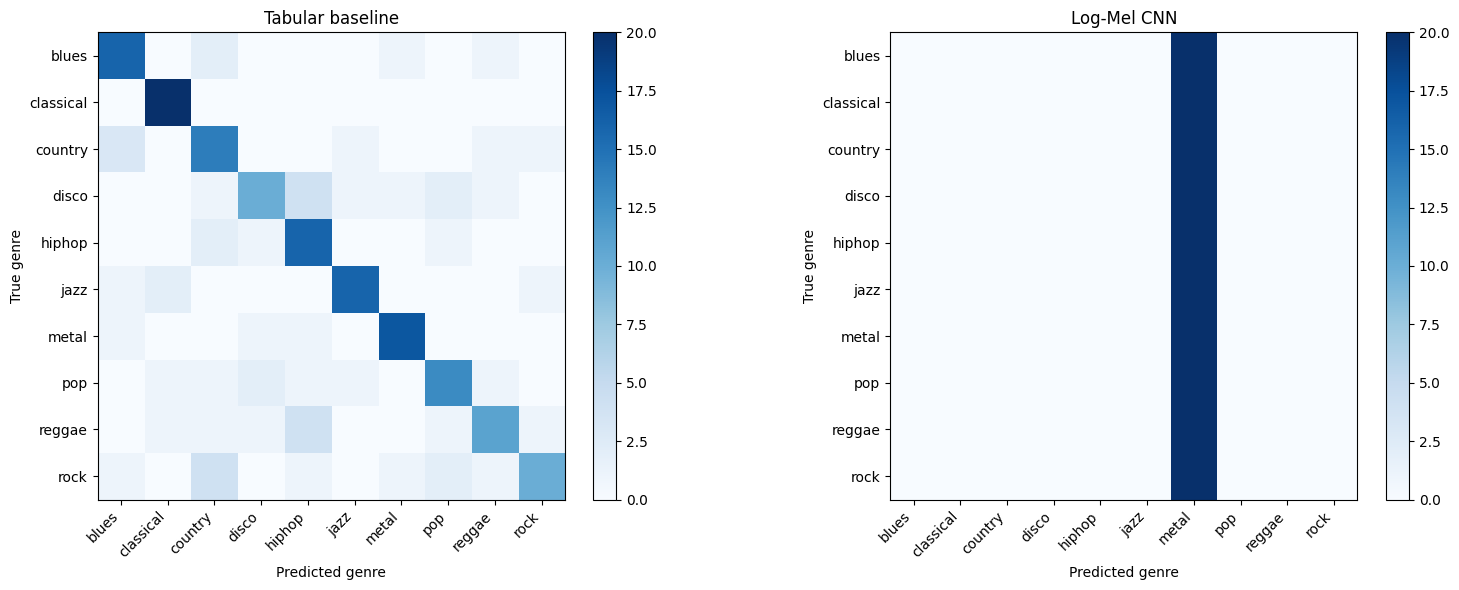

,precision,recall,f1-score,support
blues,0.727273,0.800,0.761905,20.000
classical,0.833333,1.000,0.909091,20.000
country,0.560000,0.700,0.622222,20.000
disco,0.666667,0.500,0.571429,20.000
hiphop,0.592593,0.800,0.680851,20.000
jazz,0.842105,0.800,0.820513,20.000
metal,0.850000,0.850,0.850000,20.000
pop,0.684211,0.650,0.666667,20.000
reggae,0.687500,0.550,0.611111,20.000
rock,0.769231,0.500,0.606061,20.000


,precision,recall,f1-score,support
blues,0.00,0.0,0.000000,20.0
classical,0.00,0.0,0.000000,20.0
country,0.00,0.0,0.000000,20.0
disco,0.00,0.0,0.000000,20.0
hiphop,0.00,0.0,0.000000,20.0
jazz,0.00,0.0,0.000000,20.0
metal,0.10,1.0,0.181818,20.0
pop,0.00,0.0,0.000000,20.0
reggae,0.00,0.0,0.000000,20.0
rock,0.00,0.0,0.000000,20.0


In [15]:
comparison = pd.DataFrame([
    {"approach":f"Tabular ({best_tabular_name})","test_accuracy":tabular_metrics["accuracy"],"test_macro_f1":tabular_metrics["macro_f1"],"test_macro_precision":tabular_metrics["macro_precision"],"test_macro_recall":tabular_metrics["macro_recall"]},
    {"approach":"Log-Mel CNN","test_accuracy":cnn_metrics["accuracy"],"test_macro_f1":cnn_metrics["macro_f1"],"test_macro_precision":cnn_metrics["macro_precision"],"test_macro_recall":cnn_metrics["macro_recall"]},
]).sort_values("test_macro_f1",ascending=False)
display(comparison)
fig,axes=plt.subplots(1,2,figsize=(16,6))
for ax,metrics,title in zip(axes,[tabular_metrics,cnn_metrics],["Tabular baseline","Log-Mel CNN"]):
    matrix=np.asarray(metrics["confusion_matrix"])
    image=ax.imshow(matrix,cmap="Blues")
    ax.set_title(title); ax.set_xlabel("Predicted genre"); ax.set_ylabel("True genre")
    ax.set_xticks(range(len(genre_labels)),genre_labels,rotation=45,ha="right")
    ax.set_yticks(range(len(genre_labels)),genre_labels)
    fig.colorbar(image,ax=ax,fraction=.046,pad=.04)
fig.tight_layout(); plt.show()

display(pd.DataFrame(tabular_metrics["classification_report"]).T)
display(pd.DataFrame(cnn_metrics["classification_report"]).T)


## 11. Misclassified recordings, learning curves and saved results

Use the errors to identify genre confusions. Save the comparison and metric payloads as JSON for reproducibility. These outputs remain in the Colab runtime until downloaded or saved elsewhere.

,track_id,true_genre,tabular_prediction,cnn_prediction
0,blues/blues.00001.au,blues,reggae,metal
1,blues/blues.00002.au,blues,country,metal
2,blues/blues.00014.au,blues,blues,metal
3,blues/blues.00020.au,blues,blues,metal
4,blues/blues.00021.au,blues,blues,metal
5,blues/blues.00023.au,blues,blues,metal
6,blues/blues.00029.au,blues,blues,metal
7,blues/blues.00037.au,blues,blues,metal
8,blues/blues.00051.au,blues,blues,metal
9,blues/blues.00052.au,blues,blues,metal


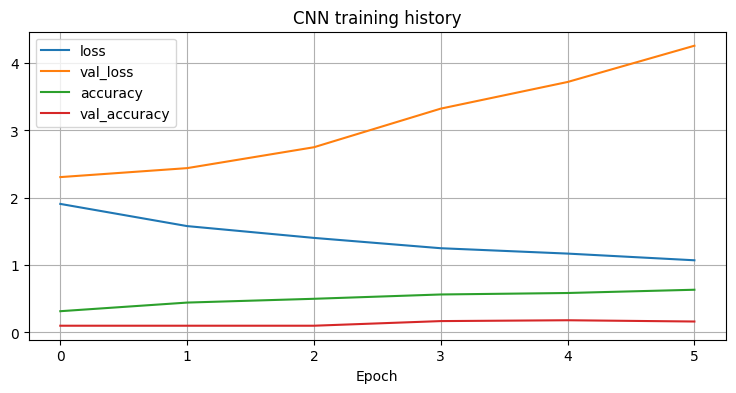

Saved artifacts: ['best_tabular_model.joblib', 'logmel_cnn.keras', 'model_comparison.csv', 'results.json', 'split_manifest.csv', 'test_predictions.csv']


In [16]:
error_table = pd.DataFrame({
    "track_id":test_tracks.track_id.to_numpy(),
    "true_genre":y_test,
    "tabular_prediction":tabular_test_pred,
    "cnn_prediction":cnn_test_pred,
})
display(error_table.loc[
    (error_table.true_genre!=error_table.tabular_prediction) |
    (error_table.true_genre!=error_table.cnn_prediction)
].head(30))

pd.DataFrame(history.history)[["loss","val_loss","accuracy","val_accuracy"]].plot(figsize=(9,4),title="CNN training history")
plt.xlabel("Epoch"); plt.grid(True); plt.show()

results = {
    "seed":SEED,
    "dataset_recordings":int(len(tracks)),
    "genre_counts":{str(k):int(v) for k,v in tracks.genre.value_counts().items()},
    "split_counts":{k:int(len(v)) for k,v in split_frames.items()},
    "tabular_model":best_tabular_name,
    "tabular_metrics":tabular_metrics,
    "cnn_metrics":cnn_metrics,
    "comparison":comparison.to_dict(orient="records"),
    "notes":["Track-level stratified split shared by both approaches.","Test set held out until final evaluation.","Exact SHA-256 duplicates audited; near-duplicates and artist leakage are not ruled out."]
}
with open("artifacts/results.json","w") as f:
    json.dump(results,f,indent=2)
comparison.to_csv("artifacts/model_comparison.csv",index=False)
error_table.to_csv("artifacts/test_predictions.csv",index=False)
print("Saved artifacts:",sorted(p.name for p in Path("artifacts").iterdir()))
